# Mobility entropy

## Destinations reached by origin population

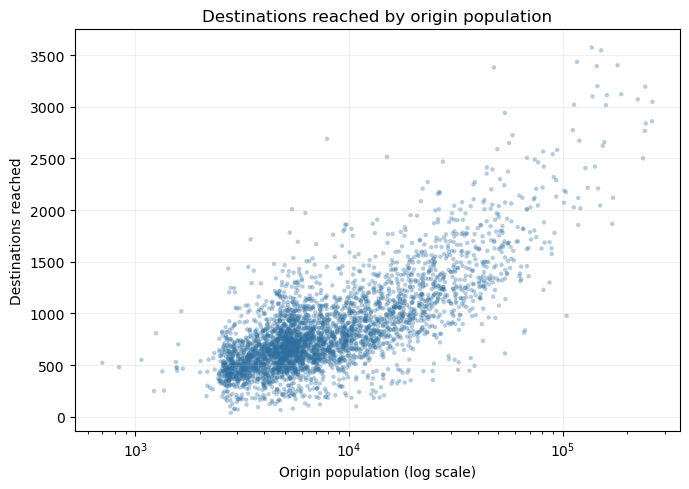

3,741 origins


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

SAVE = {"income_diversity"}  # section names to write PNGs for; empty set = write none


def save(fig, name, section=None):
    if section is None or section in SAVE:
        fig.savefig(Path.home() / "Desktop" / name, dpi=180, bbox_inches="tight")


ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data"

pairs = pd.read_parquet(
    DATA / "recent_2025-03" / "_od_pairs_cache.parquet",
    columns=["id_origin", "id_destination", "n_trips"],
)
pairs[["id_origin", "id_destination"]] = pairs[["id_origin", "id_destination"]].astype(str)
pairs = pairs[
    pairs["id_origin"].str[0].str.isdigit()
    & pairs["id_destination"].str[0].str.isdigit()
    & (pairs["id_origin"] != pairs["id_destination"])
    & (pairs["n_trips"] > 0)
]

destinations = pairs.groupby("id_origin")["id_destination"].nunique()

crosswalk = pd.read_csv(
    DATA / "geometries" / "relacion_ine_zonificacionMitma.csv",
    sep="|",
    dtype=str,
)
population = pd.read_csv(
    DATA / "demo" / "pop_seccion_2023.csv",
    dtype={"seccion_ine": str},
)
population = (
    crosswalk[["seccion_ine", "distrito_mitma"]]
    .merge(population, on="seccion_ine", how="left")
    .groupby("distrito_mitma")["poblacion"]
    .sum(min_count=1)
)

origins = (
    destinations.rename("destinations")
    .to_frame()
    .join(population.rename("population"))
    .dropna()
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    origins["population"],
    origins["destinations"],
    s=10,
    alpha=0.35,
    color="#2f6f9f",
    edgecolors="none",
)
ax.set_xscale("log")
ax.set_xlabel("Origin population (log scale)")
ax.set_ylabel("Destinations reached")
ax.set_title("Destinations reached by origin population")
ax.grid(alpha=0.2)
fig.tight_layout()

save(fig, "origin_destinations_by_population.png", "measure1")
plt.show()
print(f"{len(origins):,} origins")

## Rank–share curve: Madrid Centro

Destinations ranked by trip volume, each as a share of the origin's outgoing trips.

Madrid Centro        dests=3,572  H=3.718  effective= 41.2
Llanes (Asturias)    dests=1,211  H=3.712  effective= 40.9


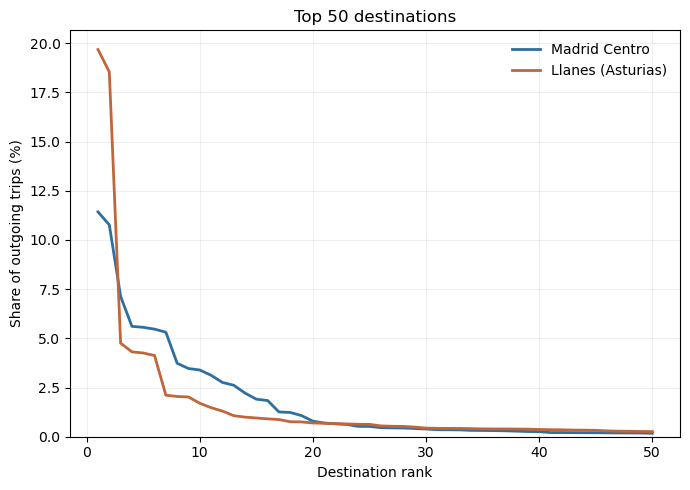

In [2]:
import numpy as np

TOP = 50
DISTRICTS = {"Madrid Centro": "2807901", "Llanes (Asturias)": "33036"}


def shares(origin):
    flows = (
        pairs.loc[pairs["id_origin"] == origin, "n_trips"]
        .sort_values(ascending=False)
        .to_numpy()
    )
    return flows / flows.sum()


fig, ax = plt.subplots(figsize=(7, 5))
for (name, origin), color in zip(DISTRICTS.items(), ["#2f6f9f", "#c1663a"]):
    s = shares(origin)
    ax.plot(np.arange(1, TOP + 1), s[:TOP] * 100, lw=2, color=color, label=name)
    H = -(s * np.log(s)).sum()
    print(f"{name:20s} dests={len(s):5,d}  H={H:.3f}  effective={np.exp(H):5.1f}")

ax.set_xlabel("Destination rank")
ax.set_ylabel("Share of outgoing trips (%)")
ax.set_title(f"Top {TOP} destinations")
ax.set_ylim(0)
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()

save(fig, "rank_share_comparison.png", "measure1")
plt.show()

## 1. H — raw entropy

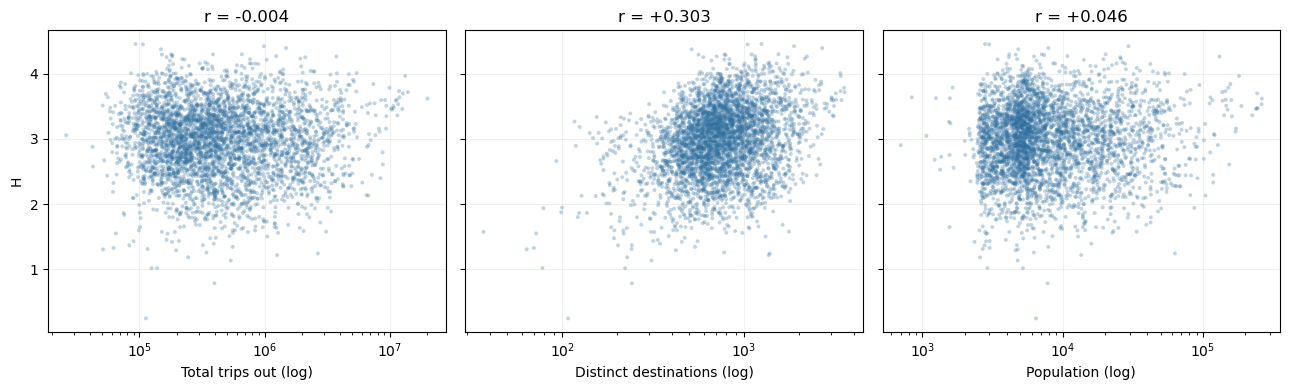

min    0.245
50%    3.000
max    4.456


In [3]:
totals = pairs.groupby("id_origin")["n_trips"].transform("sum")
p = pairs["n_trips"] / totals
grouped = pairs.assign(term=-p * np.log(p)).groupby("id_origin")

entropy = pd.DataFrame(
    {
        "H": grouped["term"].sum(),
        "trips": grouped["n_trips"].sum(),
        "destinations": grouped.size(),
    }
).join(population.rename("population"))

panels = [
    ("trips", "Total trips out (log)"),
    ("destinations", "Distinct destinations (log)"),
    ("population", "Population (log)"),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (col, label) in zip(axes, panels):
    d = entropy[["H", col]].dropna()
    ax.scatter(d[col], d["H"], s=8, alpha=0.3, color="#2f6f9f", edgecolors="none")
    ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.set_title(f"r = {np.corrcoef(np.log(d[col]), d['H'])[0, 1]:+.3f}")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("H")
fig.tight_layout()
save(fig, "entropy_1_H.png", "measure1")
plt.show()
print(entropy["H"].describe()[["min", "50%", "max"]].round(3).to_string())

## 2. S — normalised by observed destinations

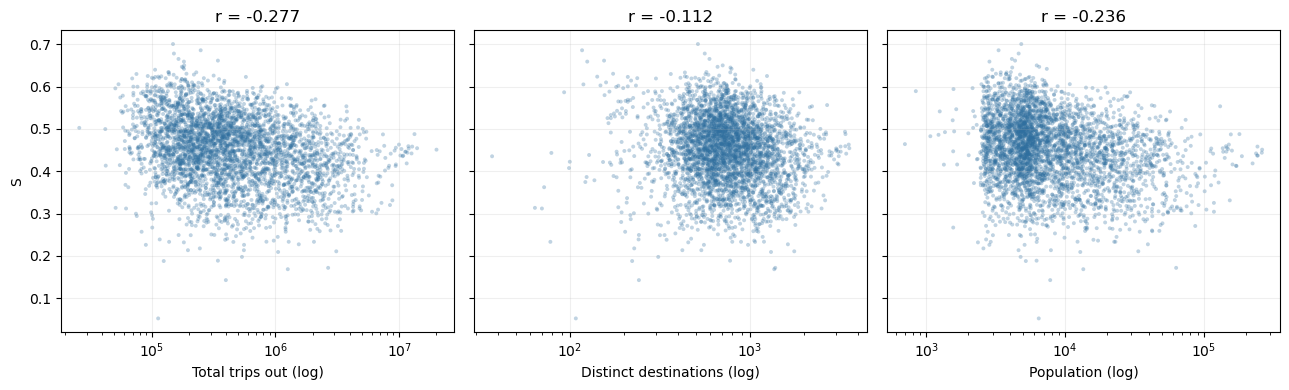

min    0.052
50%    0.455
max    0.701


In [4]:
entropy["S"] = entropy["H"] / np.log(entropy["destinations"])

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (col, label) in zip(axes, panels):
    d = entropy[["S", col]].dropna()
    ax.scatter(d[col], d["S"], s=8, alpha=0.3, color="#2f6f9f", edgecolors="none")
    ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.set_title(f"r = {np.corrcoef(np.log(d[col]), d['S'])[0, 1]:+.3f}")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("S")
fig.tight_layout()
save(fig, "entropy_2_S.png", "measure1")
plt.show()
print(entropy["S"].describe()[["min", "50%", "max"]].round(3).to_string())

## Why H and not S

Income correlates with trip volume, and S carries a volume artifact that works against it.

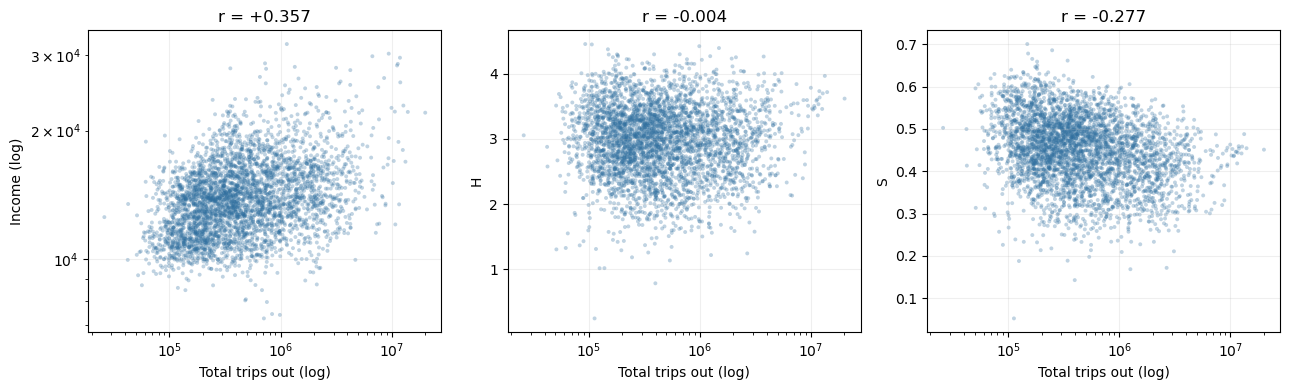

H vs log income  r = +0.165
S vs log income  r = +0.057


In [5]:
income = pd.read_csv(DATA / "renta" / "renta_seccion_2023.csv", dtype={"seccion_ine": str})
sections = (
    crosswalk[["seccion_ine", "distrito_mitma"]]
    .merge(income, on="seccion_ine")
    .merge(
        pd.read_csv(DATA / "demo" / "pop_seccion_2023.csv", dtype={"seccion_ine": str}),
        on="seccion_ine",
    )
)
sections["weighted"] = sections["renta_persona"] * sections["poblacion"]
districts = sections.groupby("distrito_mitma").agg(
    income=("weighted", "sum"), pop=("poblacion", "sum")
)
districts["income"] /= districts["pop"]

d = entropy.join(districts["income"]).dropna(subset=["income", "H", "S"])
d = d[d["income"] > 0]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
plots = [
    ("income", "Income (log)", True),
    ("H", "H", False),
    ("S", "S", False),
]
for ax, (col, label, logy) in zip(axes, plots):
    ax.scatter(d["trips"], d[col], s=8, alpha=0.3, color="#2f6f9f", edgecolors="none")
    ax.set_xscale("log")
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("Total trips out (log)")
    ax.set_ylabel(label)
    y = np.log(d[col]) if logy else d[col]
    ax.set_title(f"r = {np.corrcoef(np.log(d['trips']), y)[0, 1]:+.3f}")
    ax.grid(alpha=0.2)

fig.tight_layout()
save(fig, "why_H_not_S.png", "measure1")
plt.show()

li = np.log(d["income"])
print(f"H vs log income  r = {np.corrcoef(d['H'], li)[0, 1]:+.3f}")
print(f"S vs log income  r = {np.corrcoef(d['S'], li)[0, 1]:+.3f}")

## H against income

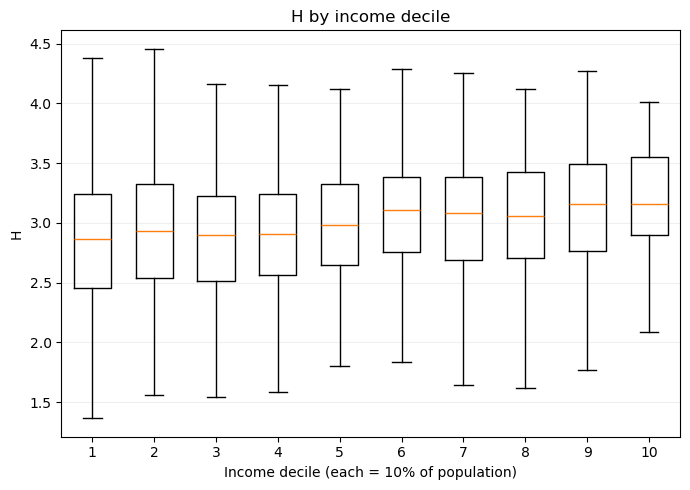

          income     H  districts
decile                           
1       10562.84  2.87        575
2       11602.78  2.93        421
3       12518.84  2.90        417
4       13206.15  2.90        361
5       13868.30  2.98        390
6       14596.78  3.11        419
7       15537.15  3.08        351
8       16479.69  3.06        328
9       18059.98  3.16        295
10      21263.71  3.16        183


In [6]:
d = d.join(districts["pop"])
order = d["income"].sort_values().index
cumulative_pop = d.loc[order, "pop"].cumsum() / d["pop"].sum()
d["decile"] = (
    pd.cut(cumulative_pop, np.linspace(0, 1, 11), labels=range(1, 11))
    .reindex(d.index)
    .astype("Int64")
)

fig, ax = plt.subplots(figsize=(7, 5))
groups = [d.loc[d["decile"] == i, "H"].dropna() for i in range(1, 11)]
ax.boxplot(groups, positions=range(1, 11), widths=0.6, showfliers=False)
ax.set_xlabel("Income decile (each = 10% of population)")
ax.set_ylabel("H")
ax.set_title("H by income decile")
ax.grid(alpha=0.2, axis="y")
fig.tight_layout()
save(fig, "H_by_income_decile.png", "measure1")
plt.show()

print(
    d.groupby("decile", observed=True)
    .agg(income=("income", "median"), H=("H", "median"), districts=("H", "size"))
    .round(2)
    .to_string()
)

## H against unemployment

Paro is municipality-level; allocated to sections by working-age share, then summed to districts. Rate uses working-age population as denominator. Districts with any municipality missing paro are dropped.

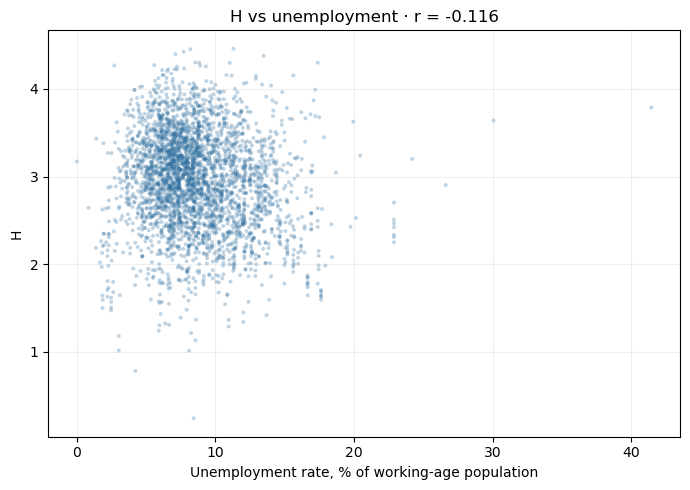

n = 3,269   R2 = 0.0305
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.5910      0.505     -1.171      0.242      -1.581       0.399
u             -1.0561      0.322     -3.281      0.001      -1.687      -0.425
log_income     0.3630      0.053      6.836      0.000       0.259       0.467
log_pop        0.0197      0.012      1.671      0.095      -0.003       0.043


In [7]:
import statsmodels.api as sm

paro = pd.read_csv(DATA / "paro" / "paro_municipios_2025-03.csv", dtype={"municipio_ine": str})
working_age = pd.read_csv(
    DATA / "demo" / "workingage_seccion_2023.csv", dtype={"seccion_ine": str}
)

s = crosswalk[["seccion_ine", "municipio_ine", "distrito_mitma"]].merge(
    working_age, on="seccion_ine", how="left"
)
s["muni_paro"] = s["municipio_ine"].map(paro.set_index("municipio_ine")["total_paro"])
s["muni_wa"] = s["municipio_ine"].map(
    s.groupby("municipio_ine")["working_age_pop"].sum(min_count=1)
)
s["allocated"] = s["muni_paro"] * s["working_age_pop"] / s["muni_wa"]

unemployment = s.groupby("distrito_mitma").agg(
    paro=("allocated", "sum"), working_age=("working_age_pop", "sum")
)
unemployment.loc[s.groupby("distrito_mitma")["allocated"].apply(lambda x: x.isna().any()), "paro"] = np.nan
unemployment["u"] = unemployment["paro"] / unemployment["working_age"]

u = d.join(unemployment["u"]).dropna(subset=["u", "H", "income", "pop"])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(u["u"] * 100, u["H"], s=8, alpha=0.3, color="#2f6f9f", edgecolors="none")
ax.set_xlabel("Unemployment rate, % of working-age population")
ax.set_ylabel("H")
ax.set_title(f"H vs unemployment · r = {np.corrcoef(u['u'], u['H'])[0, 1]:+.3f}")
ax.grid(alpha=0.2)
fig.tight_layout()
save(fig, "H_vs_unemployment.png", "measure1")
plt.show()

X = pd.DataFrame(
    {"u": u["u"], "log_income": np.log(u["income"]), "log_pop": np.log(u["pop"])}
)
model = sm.OLS(u["H"], sm.add_constant(X)).fit()
print(f"n = {len(u):,}   R2 = {model.rsquared:.4f}")
print(model.summary().tables[1])

## Same analysis with S

Decile plot, unemployment scatter, and both regressions repeated with S in place of H.

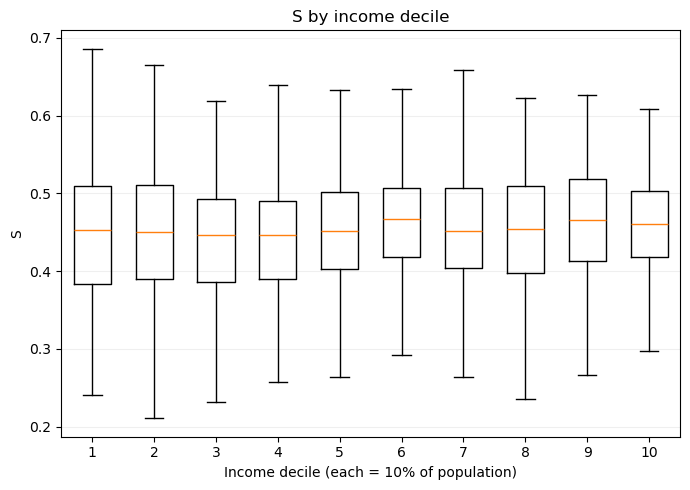

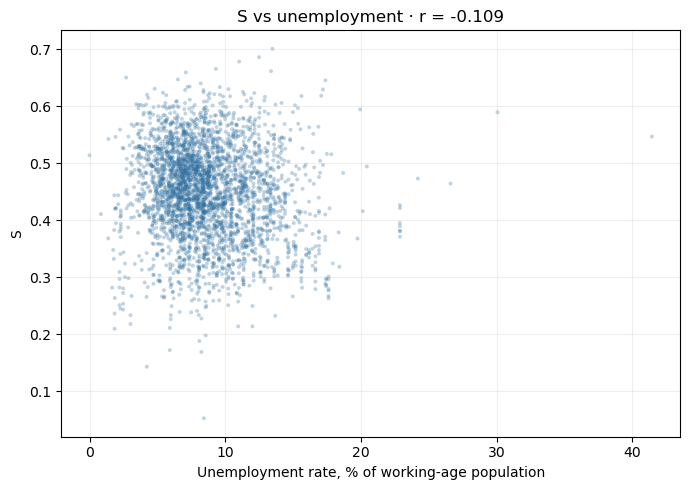

--- S ~ income model · n = 3,740 · R2 = 0.0667
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2623      0.060      4.352      0.000       0.144       0.381
log_income     0.0424      0.006      6.585      0.000       0.030       0.055
log_pop       -0.0241      0.002    -15.931      0.000      -0.027      -0.021
--- S ~ unemployment model · n = 3,269 · R2 = 0.0671
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3536      0.073      4.873      0.000       0.211       0.496
u             -0.1503      0.046     -3.249      0.001      -0.241      -0.060
log_income     0.0335      0.008      4.387      0.000       0.019       0.048
log_pop       -0.0235      0.002    -13.851      0.000      -0.027      -0.020


In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot(
    [d.loc[d["decile"] == i, "S"].dropna() for i in range(1, 11)],
    positions=range(1, 11),
    widths=0.6,
    showfliers=False,
)
ax.set_xlabel("Income decile (each = 10% of population)")
ax.set_ylabel("S")
ax.set_title("S by income decile")
ax.grid(alpha=0.2, axis="y")
fig.tight_layout()
save(fig, "S_by_income_decile.png", "measure1")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(u["u"] * 100, u["S"], s=8, alpha=0.3, color="#2f6f9f", edgecolors="none")
ax.set_xlabel("Unemployment rate, % of working-age population")
ax.set_ylabel("S")
ax.set_title(f"S vs unemployment · r = {np.corrcoef(u['u'], u['S'])[0, 1]:+.3f}")
ax.grid(alpha=0.2)
fig.tight_layout()
save(fig, "S_vs_unemployment.png", "measure1")
plt.show()

fits = {
    "income": sm.OLS(
        d["S"], sm.add_constant(pd.DataFrame({"log_income": np.log(d["income"]), "log_pop": np.log(d["pop"])}))
    ).fit(),
    "unemployment": sm.OLS(
        u["S"],
        sm.add_constant(
            pd.DataFrame({"u": u["u"], "log_income": np.log(u["income"]), "log_pop": np.log(u["pop"])})
        ),
    ).fit(),
}
for name, fit in fits.items():
    print(f"--- S ~ {name} model · n = {int(fit.nobs):,} · R2 = {fit.rsquared:.4f}")
    print(fit.summary().tables[1])

## 3. S50 — normalised by available destinations within 50 km

Both numerator and denominator restricted to the same set: shares recomputed over
destinations within 50 km, denominator is the count of zones within 50 km from geometry.

In [9]:
import geopandas as gpd
from scipy.spatial import cKDTree

RADIUS_KM = 50

zones = gpd.read_file(DATA / "geometries" / "zonificacion_distritos.shp").set_index("ID")
centroids = zones.geometry.centroid
xy = np.c_[centroids.x, centroids.y]
tree = cKDTree(xy)

neighbours = tree.query_ball_point(xy, RADIUS_KM * 1000)
n_avail = pd.Series(
    [len(n) - 1 for n in neighbours], index=zones.index, name="n_avail"
)

within = pd.DataFrame(
    [(zones.index[i], zones.index[j]) for i, ns in enumerate(neighbours) for j in ns],
    columns=["id_origin", "id_destination"],
)
local = pairs.merge(within, on=["id_origin", "id_destination"])

local_totals = local.groupby("id_origin")["n_trips"].transform("sum")
q = local["n_trips"] / local_totals
H50 = local.assign(term=-q * np.log(q)).groupby("id_origin")["term"].sum()

entropy["H50"] = H50
entropy["n_avail"] = n_avail
entropy["S50"] = entropy["H50"] / np.log(entropy["n_avail"])

print(f"trips kept within {RADIUS_KM} km: {100 * local['n_trips'].sum() / pairs['n_trips'].sum():.1f}%")
print(f"n_avail  min={n_avail.min()}  median={int(n_avail.median())}  max={n_avail.max()}")
print(f"zones with n_avail < 2: {(n_avail < 2).sum()}")
print(entropy[["H", "S", "S50"]].describe().loc[["min", "50%", "max"]].round(3).to_string())

/opt/miniconda3/envs/spain-mobility/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: /Users/theocoronges/Documents/internship2026/data/geometries/zonificacion_distritos.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


trips kept within 50 km: 96.8%
n_avail  min=0  median=64  max=310
zones with n_avail < 2: 104
         H      S    S50
min  0.245  0.052  0.214
50%  3.000  0.455  0.634
max  4.456  0.701  0.951


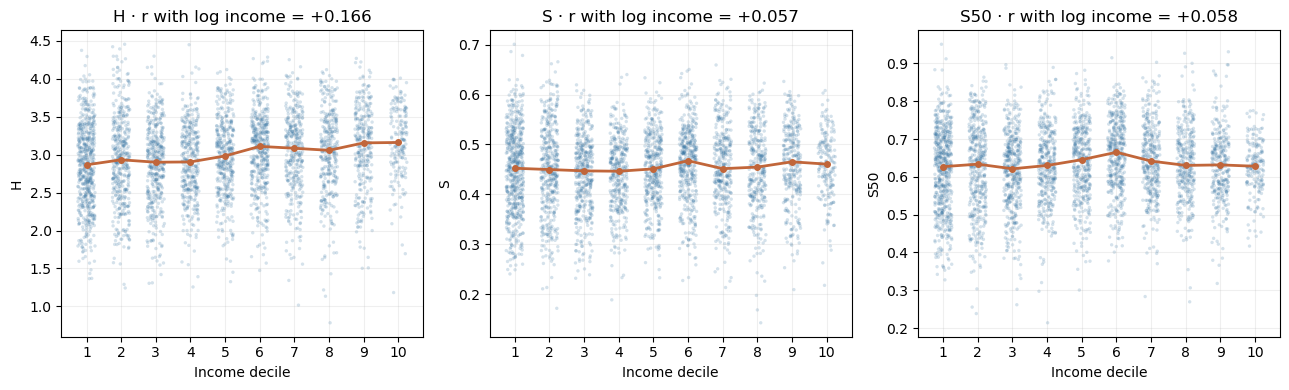

           income      H      S    S50
decile                                
1       10562.838  2.866  0.452  0.627
2       11602.776  2.933  0.450  0.634
3       12520.111  2.901  0.447  0.621
4       13206.150  2.905  0.446  0.630
5       13868.304  2.983  0.451  0.645
6       14592.120  3.110  0.467  0.665
7       15537.145  3.085  0.452  0.642
8       16479.689  3.058  0.455  0.630
9       18059.977  3.156  0.465  0.632
10      21263.715  3.161  0.461  0.628


In [10]:
c = d.join(entropy[["S50"]]).dropna(subset=["S50", "decile"])

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["H", "S", "S50"]):
    ax.scatter(
        c["decile"] + np.random.uniform(-0.25, 0.25, len(c)),
        c[col],
        s=6,
        alpha=0.2,
        color="#2f6f9f",
        edgecolors="none",
    )
    medians = c.groupby("decile", observed=True)[col].median()
    ax.plot(medians.index, medians.values, color="#c1663a", lw=2, marker="o", ms=4)
    ax.set_xlabel("Income decile")
    ax.set_ylabel(col)
    ax.set_xticks(range(1, 11))
    r = np.corrcoef(np.log(c["income"]), c[col])[0, 1]
    ax.set_title(f"{col} · r with log income = {r:+.3f}")
    ax.grid(alpha=0.2)

fig.tight_layout()
save(fig, "H_S_S50_by_income_decile.png", "measure1")
plt.show()

print(
    c.groupby("decile", observed=True)
    .agg(income=("income", "median"), H=("H", "median"), S=("S", "median"), S50=("S50", "median"))
    .round(3)
    .to_string()
)

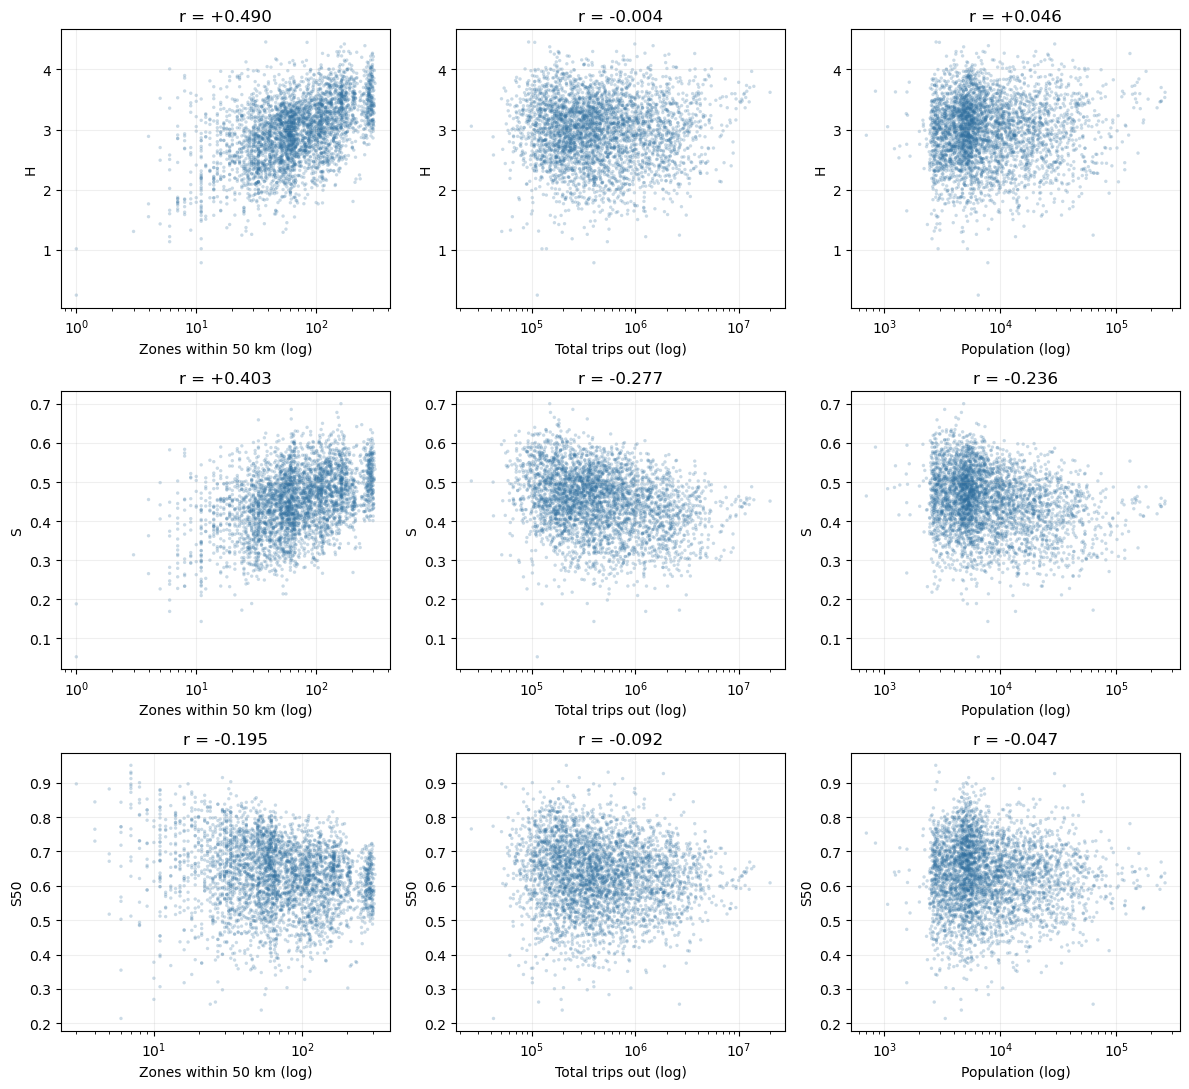

In [11]:
e = entropy.replace([np.inf, -np.inf], np.nan)
confounds = [
    ("n_avail", "Zones within 50 km (log)"),
    ("trips", "Total trips out (log)"),
    ("population", "Population (log)"),
]

fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for row, measure in zip(axes, ["H", "S", "S50"]):
    for ax, (col, label) in zip(row, confounds):
        x = e[[col, measure]].dropna()
        x = x[x[col] > 0]
        ax.scatter(x[col], x[measure], s=6, alpha=0.25, color="#2f6f9f", edgecolors="none")
        ax.set_xscale("log")
        ax.set_xlabel(label)
        ax.set_ylabel(measure)
        ax.set_title(f"r = {np.corrcoef(np.log(x[col]), x[measure])[0, 1]:+.3f}")
        ax.grid(alpha=0.2)

fig.tight_layout()
save(fig, "confounds_H_S_S50.png", "measure1")
plt.show()

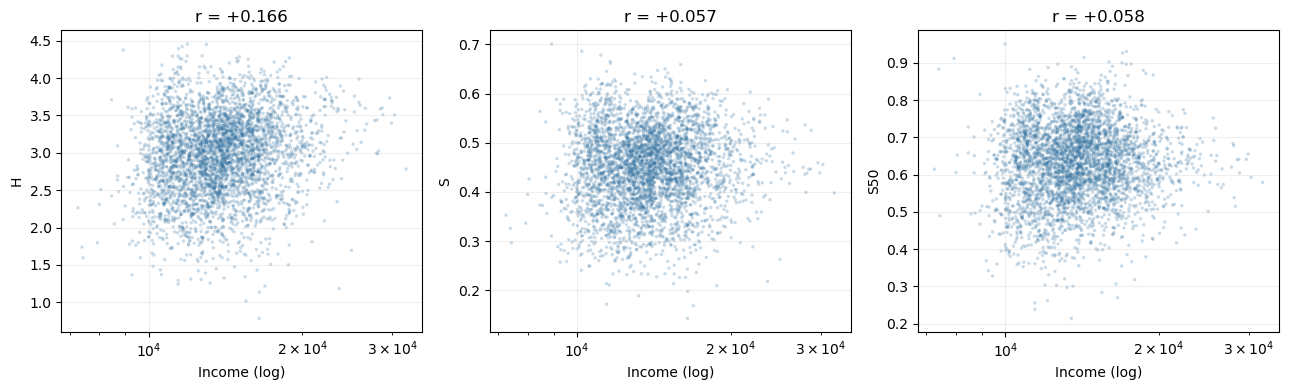

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["H", "S", "S50"]):
    x = c[["income", col]].dropna()
    ax.scatter(x["income"], x[col], s=6, alpha=0.25, color="#2f6f9f", edgecolors="none")
    ax.set_xscale("log")
    ax.set_xlabel("Income (log)")
    ax.set_ylabel(col)
    ax.set_title(f"r = {np.corrcoef(np.log(x['income']), x[col])[0, 1]:+.3f}")
    ax.grid(alpha=0.2)

fig.tight_layout()
save(fig, "income_direct_H_S_S50.png", "measure1")
plt.show()

## S50 against income

Same regression as H, with the geographic dependence normalised out of the measure.

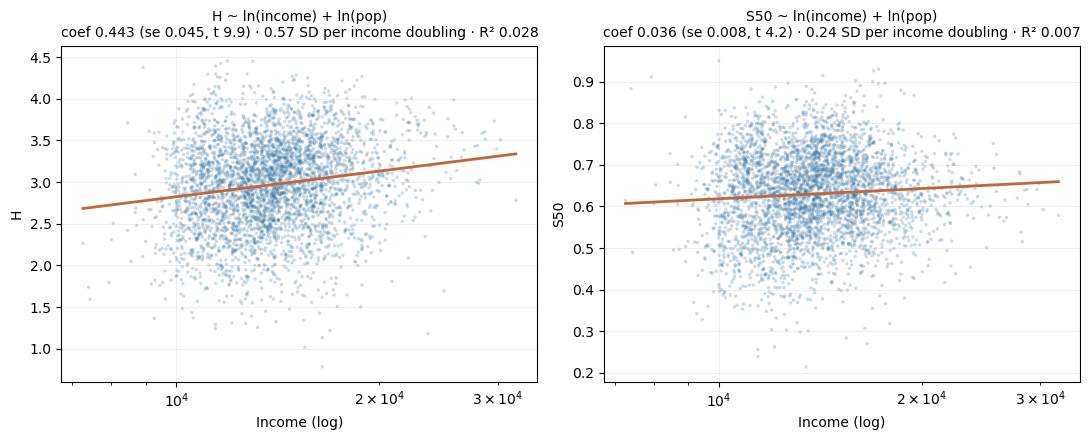

H    n=3,738  R2=0.0277  income coef=0.4428 (se 0.0446, t 9.92)
      effect of doubling income: 0.3069 = 0.571 SD of H
S50  n=3,738  R2=0.0068  income coef=0.0355 (se 0.0085, t 4.19)
      effect of doubling income: 0.0246 = 0.244 SD of S50


In [13]:
reg = c.dropna(subset=["S50", "income", "pop"])
X = sm.add_constant(pd.DataFrame({"log_income": np.log(reg["income"]), "log_pop": np.log(reg["pop"])}))
models = {m: sm.OLS(reg[m], X).fit() for m in ["H", "S50"]}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, fit) in zip(axes, models.items()):
    ax.scatter(reg["income"], reg[name], s=6, alpha=0.25, color="#2f6f9f", edgecolors="none")
    grid = np.linspace(reg["income"].min(), reg["income"].max(), 100)
    ax.plot(
        grid,
        fit.params["const"]
        + fit.params["log_income"] * np.log(grid)
        + fit.params["log_pop"] * np.log(reg["pop"]).mean(),
        color="#c1663a",
        lw=2,
    )
    ax.set_xscale("log")
    ax.set_xlabel("Income (log)")
    ax.set_ylabel(name)
    b, se = fit.params["log_income"], fit.bse["log_income"]
    sd = reg[name].std()
    ax.set_title(
        f"{name} ~ ln(income) + ln(pop)\n"
        f"coef {b:.3f} (se {se:.3f}, t {b / se:.1f}) · "
        f"{b * np.log(2) / sd:.2f} SD per income doubling · R² {fit.rsquared:.3f}",
        fontsize=10,
    )
    ax.grid(alpha=0.2)

fig.tight_layout()
save(fig, "regression_S50_vs_H_income.png", "measure1")
plt.show()

for name, fit in models.items():
    b, se = fit.params["log_income"], fit.bse["log_income"]
    print(f"{name:4s} n={int(fit.nobs):,}  R2={fit.rsquared:.4f}  income coef={b:.4f} (se {se:.4f}, t {b/se:.2f})")
    print(f"      effect of doubling income: {b * np.log(2):.4f} = {b * np.log(2) / reg[name].std():.3f} SD of {name}")

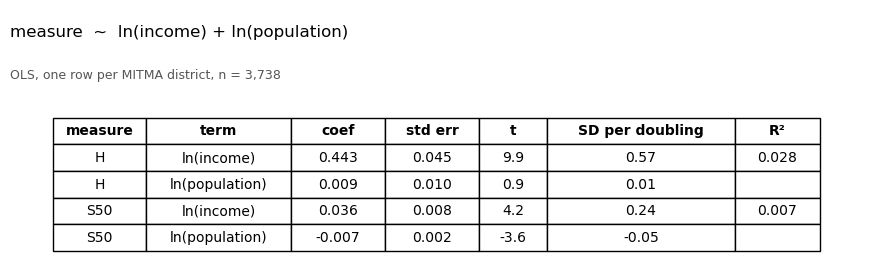

--- H · n = 3,738 · R2 = 0.0277
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.3356      0.418     -3.197      0.001      -2.155      -0.516
log_income     0.4428      0.045      9.924      0.000       0.355       0.530
log_pop        0.0092      0.010      0.881      0.378      -0.011       0.030
--- S50 · n = 3,738 · R2 = 0.0068
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3557      0.079      4.484      0.000       0.200       0.511
log_income     0.0355      0.008      4.194      0.000       0.019       0.052
log_pop       -0.0072      0.002     -3.601      0.000      -0.011      -0.003


In [14]:
rows = []
for name, fit in models.items():
    sd = reg[name].std()
    for term, label in [("log_income", "ln(income)"), ("log_pop", "ln(population)")]:
        b, se = fit.params[term], fit.bse[term]
        rows.append([
            name,
            label,
            f"{b:.3f}",
            f"{se:.3f}",
            f"{b / se:.1f}",
            f"{b * np.log(2) / sd:.2f}",
            f"{fit.rsquared:.3f}" if term == "log_income" else "",
        ])

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.axis("off")
ax.text(0, 0.94, "measure  ~  ln(income) + ln(population)", fontsize=12, va="top")
ax.text(0, 0.76, f"OLS, one row per MITMA district, n = {int(models['H'].nobs):,}", fontsize=9, va="top", color="#555555")

table = ax.table(
    cellText=rows,
    colLabels=["measure", "term", "coef", "std err", "t", "SD per doubling", "R²"],
    cellLoc="center",
    loc="lower center",
    colWidths=[0.11, 0.17, 0.11, 0.11, 0.08, 0.22, 0.10],
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)
for j in range(7):
    table[0, j].set_text_props(weight="bold")

save(fig, "regression_S50_table.png", "measure1")
plt.show()

for name, fit in models.items():
    print(f"--- {name} · n = {int(fit.nobs):,} · R2 = {fit.rsquared:.4f}")
    print(fit.summary().tables[1])

# Measure 2b — income diversity of arrivals

Entropy over the income bands of people arriving at each destination. Three bands
(<10k, 10-15k, >15k EUR/yr), so the maximum is `ln 3` for every zone -- no
geography-dependent denominator.


In [15]:
import pyarrow.dataset as ds

BANDS = ["<10", "10-15", ">15"]

arrivals = (
    ds.dataset(DATA / "recent_2025-03" / "Viajes_distritos_2025-03_age_income_v2.parquet")
    .to_table(columns=["destino", "origen", "renta", "n_trips"])
    .to_pandas()
)
arrivals = arrivals[
    arrivals["destino"].str[0].str.isdigit()
    & arrivals["origen"].str[0].str.isdigit()
    & (arrivals["destino"] != arrivals["origen"])
    & (arrivals["n_trips"] > 0)
]
arrivals = (
    arrivals.groupby(["destino", "renta"])["n_trips"].sum()
    .unstack("renta")
    .reindex(columns=BANDS)
    .fillna(0.0)
)

totals = arrivals.sum(axis=1)
p = arrivals.div(totals, axis=0)

entropy["D"] = -(p * np.log(p.where(p > 0))).sum(axis=1) / np.log(3)
entropy["trips_in"] = totals

print(f"{entropy['D'].notna().sum():,} destinations")
print(entropy["D"].describe()[["min", "25%", "50%", "75%", "max"]].round(3).to_string())
print()
print("mean band shares:", p.mean().round(3).to_dict())


3,742 destinations
min    0.041
25%    0.273
50%    0.439
75%    0.598
max    0.996

mean band shares: {'<10': 0.179, '10-15': 0.67, '>15': 0.15}


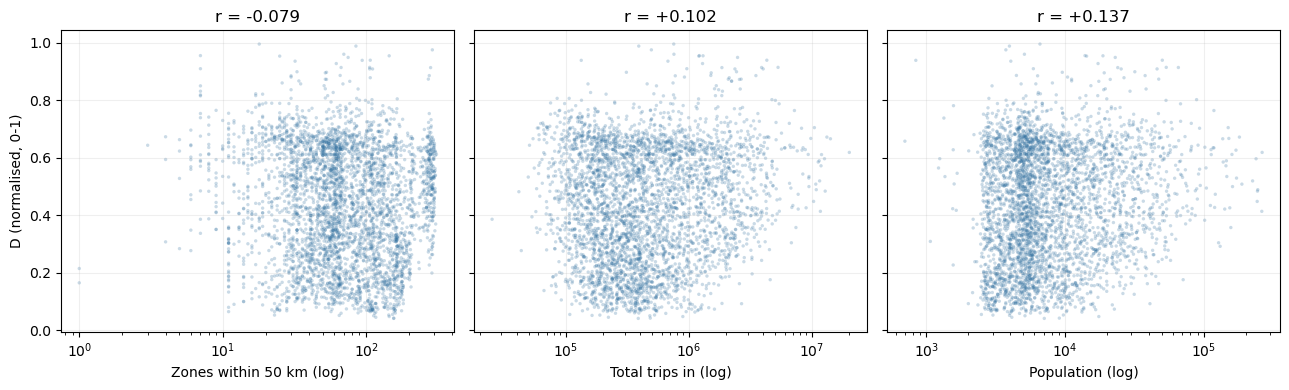

In [16]:
panels = [
    ("n_avail", "Zones within 50 km (log)"),
    ("trips_in", "Total trips in (log)"),
    ("population", "Population (log)"),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (col, label) in zip(axes, panels):
    x = entropy[[col, "D"]].dropna()
    x = x[x[col] > 0]
    ax.scatter(x[col], x["D"], s=6, alpha=0.25, color="#2f6f9f", edgecolors="none")
    ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.set_title(f"r = {np.corrcoef(np.log(x[col]), x['D'])[0, 1]:+.3f}")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("D (normalised, 0-1)")
fig.tight_layout()
save(fig, "income_diversity_confounds.png", "income_diversity")
plt.show()
